# VM2R comparison

The goal:

-> Is to compare the impact the VM2R if we perform for linear, log scale and log VM2R

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors
import matplotlib.ticker as mticker
from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting



# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])


import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch



#from concurrent.futures import ProcessPoolExecutor


In [2]:
# The functions 

# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=16)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()



            plt.savefig(
            f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.png",
            dpi=300,
            bbox_inches="tight"
        )

            plt.savefig(
                f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.pdf",
                dpi=300,
                bbox_inches="tight"
            )



    return results_outliers


# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask


# Compute VM^2R for single-dish data
def variance_to_median_square_ratio_single_dish(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the variance-to-median-square ratio (VM^2R) over time for a
    single-dish dataset.

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Input dynamic spectrum. If a Dataset is provided, the first data variable
        is used. Expected dimensions include time and frequency, and optionally
        polarization.
    time_dim : str, optional
        Name of the time dimension. Default is "time".
    freq_dim : str, optional
        Name of the frequency dimension. Default is "freq".
    pol_dim : str or None, optional
        Name of the polarization/feed dimension, if present. If None, the
        function assumes no extra per-feed/pol dimension. Default is None.
    eps : float, optional
        Small positive floor used to avoid division by zero. Default is 1e-12.

    Returns
    -------
    xr.Dataset
        Contains:
        - median: time-median per (freq[, pol])
        - variance: time-variance per (freq[, pol])
        - vm2r: variance / median^2 per (freq[, pol])
        - vm2r_by_freq: median VM^2R over polarization/feed (if pol_dim exists),
                        otherwise same as vm2r
        - vm2r_by_pol: median VM^2R over frequency (if pol_dim exists)
        - vm2r_global: global median VM^2R

    Notes
    -----
    VM^2R = Var(X) / Median(X)^2

    For single-dish total-power data this is useful for flagging non-stationary,
    bursty, or RFI-like behaviour in the time-frequency plane.
    """
    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dims
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)
    if missing:
        raise ValueError(f"Input is missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(f"pol_dim='{pol_dim}' not found in input dimensions {data_da.dims}")

    # Compute time statistics
    x = data_da.chunk({time_dim: -1})
    time_median = x.median(dim=time_dim, skipna=True).rename("median")
    time_variance = x.var(dim=time_dim, skipna=True).rename("variance")

    # VM^2R
    denom = time_median**2
    vm2r = (time_variance / denom).rename("vm2r")
    vm2r = vm2r.where(np.abs(time_median) > eps)

    out = {
        "median": time_median,
        "variance": time_variance,
        "vm2r": vm2r,
    }

    # 1D summaries
    if pol_dim is not None:
        vm2r_by_pol = (
            vm2r.chunk({freq_dim: -1})
            .median(dim=freq_dim, skipna=True)
            .rename("vm2r_by_pol")
        )
        vm2r_by_freq = (
            vm2r.chunk({pol_dim: -1})
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_freq")
        )
        out["vm2r_by_pol"] = vm2r_by_pol
        out["vm2r_by_freq"] = vm2r_by_freq
    else:
        out["vm2r_by_freq"] = vm2r.rename("vm2r_by_freq")

    # Global median
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.compute().values),
        name="vm2r_global"
    )
    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [5]:
# DATA
filename = "EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False

In [6]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [ ]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [ ]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 164MB
Dimensions:           (time: 638, frequency: 63877, integration_time: 638,
                       ra: 638, dec: 638, elevation: 638, azimuth: 638)
Coordinates:
  * time              (time) float64 5kB 1.682e+09 1.682e+09 ... 1.682e+09
  * frequency         (frequency) float64 511kB 1.793 1.793 ... 3.498 3.498
  * integration_time  (integration_time) float64 5kB 0.1152 0.1135 ... 0.1159
  * ra                (ra) float64 5kB 84.48 84.46 84.45 ... 86.42 86.43 86.43
  * dec               (dec) float64 5kB -3.161 -3.144 -3.135 ... -0.6778 -0.6739
  * elevation         (elevation) float64 5kB 24.22 24.2 24.18 ... 24.17 24.17
  * azimuth           (azimuth) float64 5kB -78.62 -78.62 ... -75.42 -75.41
Data variables:
    spectrum          (time, frequency) float32 163MB 1.942e+11 ... 4.251e+09

### Define the variables

In [ ]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_ghz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


# Perform the VM2R to linear scale

In [ ]:
vm2r_list_high = [] # list to store the VM^2R values for high level RFI
vm2r_list_low = [] # list to store the VM^2R values for high level RFI


n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 20
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)


window = 50
high_peak_freqiency = []
for k in idx:

    # Avoid overflow at the end
    if k + window > n_time:
        continue

    spectra_block = spectrum[k:k+window, :]
    spectra_block_mean = np.mean(spectra_block, axis=0)
    spectra_block_correction = base_correction(frequency, spectra_block_mean)




    da_high = xr.DataArray(
        spectra_block,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': frequency
        }
    )

    vm2r_results_high = variance_to_median_square_ratio_single_dish(
        da_high,
        time_dim='time',
        freq_dim='frequency'
    )
    vm2r_freq = vm2r_results_high['vm2r_by_freq'].values
    vm2r_list_high.append(vm2r_freq)
    

    #-----------------------------------------------------------------#
    #                                                                 #
    #         Flag the high level RFI                                 #
    #                                                                 #
    #                                                                 #
    #-----------------------------------------------------------------#     


    # Find peaks above 1 sigma from the MAD
    sigma_value = 5
    sigma = 1.4826*np.median(np.abs(spectra_block_correction - np.median(spectra_block_correction)))
    peak, propreties = find_peaks(spectra_block_correction, 
                                height=MAD(spectra_block_correction) + sigma_value*sigma,
                                distance=10,
                                prominence=1
                                )
    
    peak_freqs = [f"{f:.4f}" for f in frequency[peak]]
    print(f'Peak frequencies to analyze: {peak_freqs}')
    peak_freqs = [float(f) for f in peak_freqs]
    high_peak = quantify_all_outliers(frequency, spectra_block_correction, peak_freqs, plot=False)
    
    mask_high = build_rfi_mask(frequency, high_peak)

    # mask_signal = spectra_block[:,~mask_high]
    # mask_frequency = frequency[~mask_high]

    mask_signal = spectra_block.copy()

    # Replace RFI channels with NaN
    mask_signal[:, mask_high] = np.nan

    # plt.figure(figsize=(10, 6))
    # plt.plot(mask_frequency, mask_signal.mean(axis=0))
    # plt.plot(frequency_ghz[peak_freqs], spectra_block_correction[peak_freqs], 'x', color='red', label='Detected Peaks $>3σ$')


    #break


    mask_frequency = frequency

    # # print(f'spectra block shape: {spectra_block.shape}')
    # #print(f'Frequency at high peaks: {frequency[peak_freqs]} GHz')


    da_low = xr.DataArray(
        mask_signal,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': mask_frequency
        }
    )

    vm2r_results_low = variance_to_median_square_ratio_single_dish(
        da_low,
        time_dim='time',
        freq_dim='frequency'
    )

    vm2r_freq = vm2r_results_low['vm2r_by_freq'].values

    vm2r_list_low.append(vm2r_freq)

    #break

#convert list to array
vm2r_array_high = np.array(vm2r_list_high)
vm2r_array_low = np.array(vm2r_list_low)

Peak frequencies to analyze: ['1.7929', '1.7932', '1.7937', '1.8176', '1.8180', '1.8183', '1.8186', '1.8197', '1.8207', '1.8210', '1.8213', '1.8218', '1.8222', '1.8224', '1.8227', '1.8230', '1.8232', '1.8235', '1.8238', '1.8241', '1.8244', '1.8248', '1.8250', '1.8253', '1.8256', '1.8438', '1.8441', '1.8445', '1.8448', '1.8451', '1.8454', '1.8459', '1.8464', '1.8467', '1.8472', '1.8477', '1.8481', '1.8486', '1.8489', '1.8492', '1.8495', '1.8499', '1.8875', '1.8878', '1.8882', '1.8887', '1.8890', '1.8893', '1.8897', '1.8901', '1.8904', '1.8907', '1.8910', '1.8914', '1.8918', '1.8922', '1.8925', '1.8927', '1.8930', '1.8933', '1.8937', '1.9525', '1.9530', '1.9533', '1.9536', '1.9542', '1.9547', '1.9551', '1.9927', '2.0011', '2.0017', '2.0029', '2.0044', '2.0047', '2.0115', '2.0118', '2.0122', '2.0124', '2.0130', '2.0135', '2.0138', '2.0140', '2.0147', '2.0150', '2.0153', '2.0157', '2.0159', '2.0172', '2.0702', '2.0705', '2.0708', '2.0922', '2.0926', '2.0929', '2.0933', '2.0938', '2.0942', 

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.7928', '1.7931', '1.7934', '1.7936', '1.8176', '1.8181', '1.8184', '1.8186', '1.8197', '1.8207', '1.8210', '1.8214', '1.8217', '1.8219', '1.8222', '1.8225', '1.8228', '1.8231', '1.8235', '1.8238', '1.8241', '1.8244', '1.8246', '1.8249', '1.8253', '1.8256', '1.8432', '1.8435', '1.8438', '1.8441', '1.8446', '1.8449', '1.8452', '1.8456', '1.8459', '1.8464', '1.8469', '1.8474', '1.8477', '1.8480', '1.8483', '1.8486', '1.8491', '1.8495', '1.8497', '1.8875', '1.8880', '1.8885', '1.8888', '1.8893', '1.8897', '1.8900', '1.8904', '1.8908', '1.8911', '1.8915', '1.8918', '1.8921', '1.8926', '1.8929', '1.8932', '1.8934', '1.9526', '1.9529', '1.9532', '1.9536', '1.9542', '1.9548', '1.9552', '1.9929', '1.9932', '2.0010', '2.0029', '2.0043', '2.0047', '2.0109', '2.0114', '2.0118', '2.0121', '2.0125', '2.0128', '2.0132', '2.0136', '2.0140', '2.0143', '2.0147', '2.0150', '2.0154', '2.0159', '2.0167', '2.0175', '2.0702', '2.0705', '2.0708', '2.0922', '2.0926', '2.0929', 

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.7928', '1.7933', '1.8176', '1.8181', '1.8183', '1.8188', '1.8197', '1.8207', '1.8210', '1.8214', '1.8217', '1.8221', '1.8224', '1.8228', '1.8230', '1.8233', '1.8236', '1.8241', '1.8245', '1.8249', '1.8253', '1.8439', '1.8444', '1.8447', '1.8450', '1.8454', '1.8459', '1.8463', '1.8466', '1.8471', '1.8473', '1.8478', '1.8481', '1.8486', '1.8489', '1.8493', '1.8497', '1.8876', '1.8879', '1.8883', '1.8886', '1.8889', '1.8892', '1.8895', '1.8899', '1.8903', '1.8906', '1.8910', '1.8914', '1.8917', '1.8920', '1.8923', '1.8926', '1.8929', '1.8932', '1.8936', '1.8939', '1.9521', '1.9524', '1.9527', '1.9530', '1.9535', '1.9539', '1.9543', '1.9546', '1.9551', '1.9907', '1.9914', '1.9921', '1.9928', '2.0012', '2.0016', '2.0019', '2.0029', '2.0043', '2.0047', '2.0110', '2.0114', '2.0118', '2.0121', '2.0126', '2.0131', '2.0134', '2.0139', '2.0143', '2.0148', '2.0151', '2.0154', '2.0159', '2.0162', '2.0165', '2.0701', '2.0704', '2.0708', '2.0927', '2.0930', '2.0933', 

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


... (26 outputs left out)

Peak frequencies to analyze: ['1.7928', '1.7931', '1.7934', '1.7936', '1.8176', '1.8178', '1.8181', '1.8184', '1.8188', '1.8197', '1.8206', '1.8210', '1.8213', '1.8217', '1.8220', '1.8223', '1.8226', '1.8230', '1.8233', '1.8236', '1.8239', '1.8242', '1.8245', '1.8248', '1.8251', '1.8254', '1.8257', '1.8434', '1.8436', '1.8440', '1.8444', '1.8448', '1.8452', '1.8455', '1.8460', '1.8462', '1.8465', '1.8470', '1.8474', '1.8478', '1.8481', '1.8484', '1.8488', '1.8491', '1.8497', '1.8737', '1.8761', '1.8875', '1.8878', '1.8882', '1.8888', '1.8891', '1.8893', '1.8897', '1.8900', '1.8906', '1.8910', '1.8914', '1.8918', '1.8922', '1.8926', '1.8929', '1.8932', '1.8935', '1.9520', '1.9523', '1.9528', '1.9531', '1.9535', '1.9539', '1.9543', '1.9546', '1.9553', '1.9906', '1.9914', '1.9923', '1.9928', '1.9931', '2.0010', '2.0013', '2.0015', '2.0029', '2.0044', '2.0047', '2.0113', '2.0117', '2.0122', '2.0126', '2.0130', '2.0134', '2.0138', '2.0141', '2.0146', '2.0151', '2.0155', '2.0159', '2.0165', 

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.7928', '1.7931', '1.7934', '1.7937', '1.8174', '1.8178', '1.8181', '1.8184', '1.8187', '1.8197', '1.8206', '1.8209', '1.8214', '1.8216', '1.8219', '1.8222', '1.8226', '1.8230', '1.8235', '1.8238', '1.8242', '1.8245', '1.8248', '1.8251', '1.8254', '1.8436', '1.8439', '1.8444', '1.8448', '1.8452', '1.8456', '1.8459', '1.8464', '1.8467', '1.8470', '1.8473', '1.8478', '1.8481', '1.8485', '1.8488', '1.8491', '1.8494', '1.8497', '1.8736', '1.8761', '1.8873', '1.8876', '1.8881', '1.8885', '1.8889', '1.8892', '1.8896', '1.8900', '1.8903', '1.8907', '1.8912', '1.8914', '1.8917', '1.8920', '1.8923', '1.8926', '1.8929', '1.8933', '1.8939', '1.9519', '1.9526', '1.9530', '1.9535', '1.9542', '1.9547', '1.9945', '2.0011', '2.0015', '2.0029', '2.0044', '2.0106', '2.0113', '2.0118', '2.0122', '2.0125', '2.0128', '2.0134', '2.0138', '2.0142', '2.0145', '2.0149', '2.0154', '2.0161', '2.0165', '2.0169', '2.0173', '2.0182', '2.0701', '2.0704', '2.0708', '2.0927', '2.0930', 

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


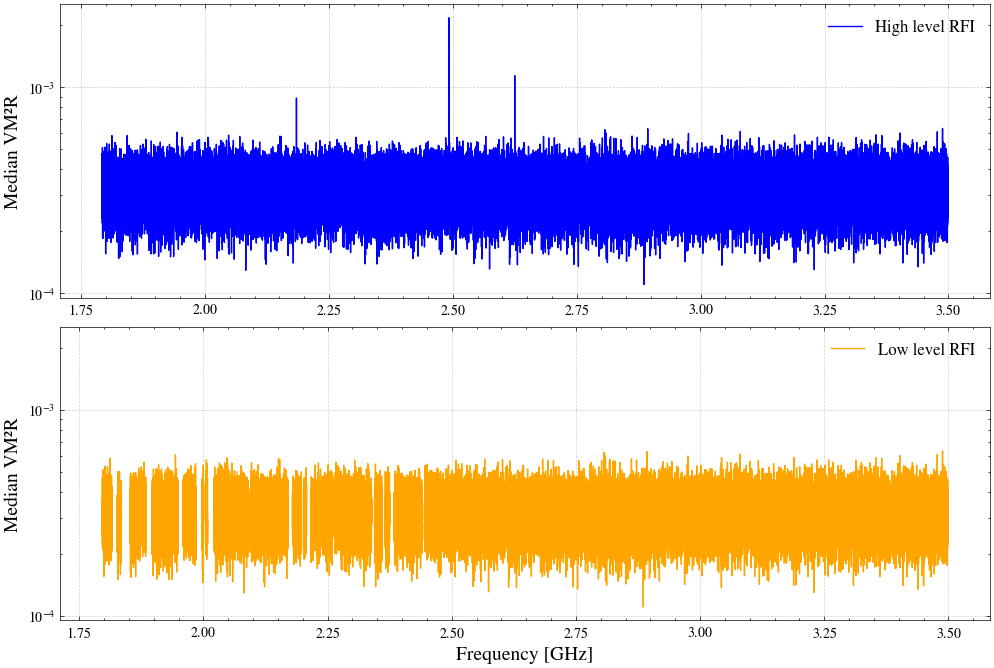

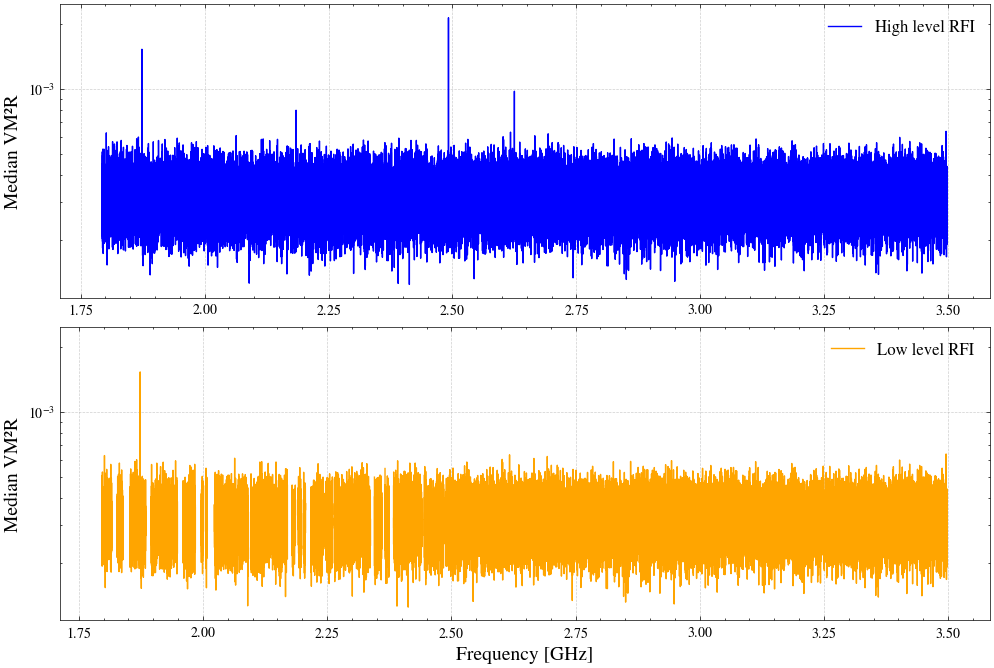

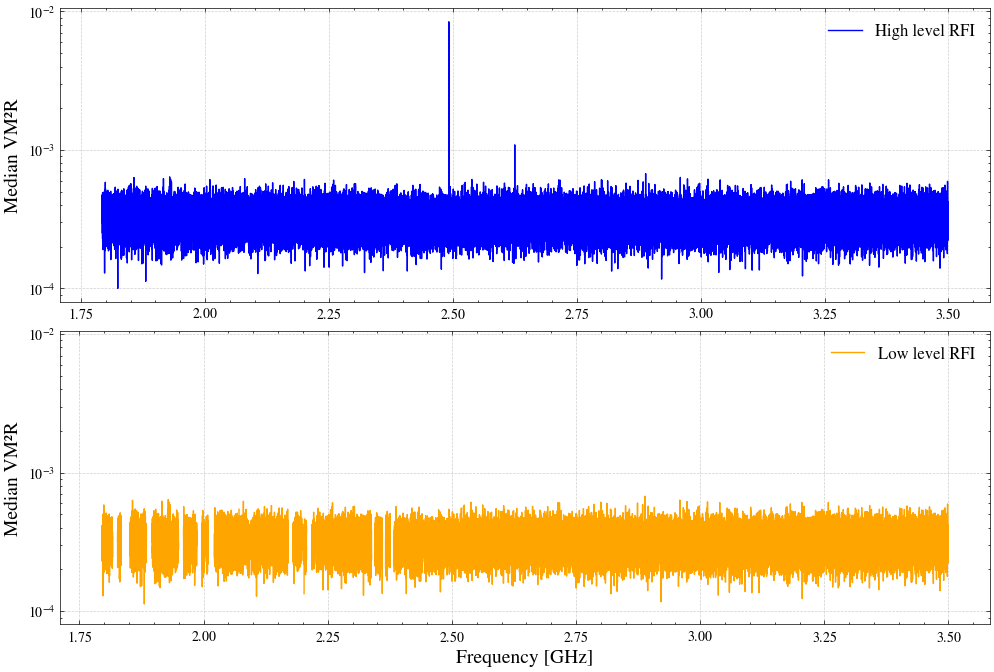

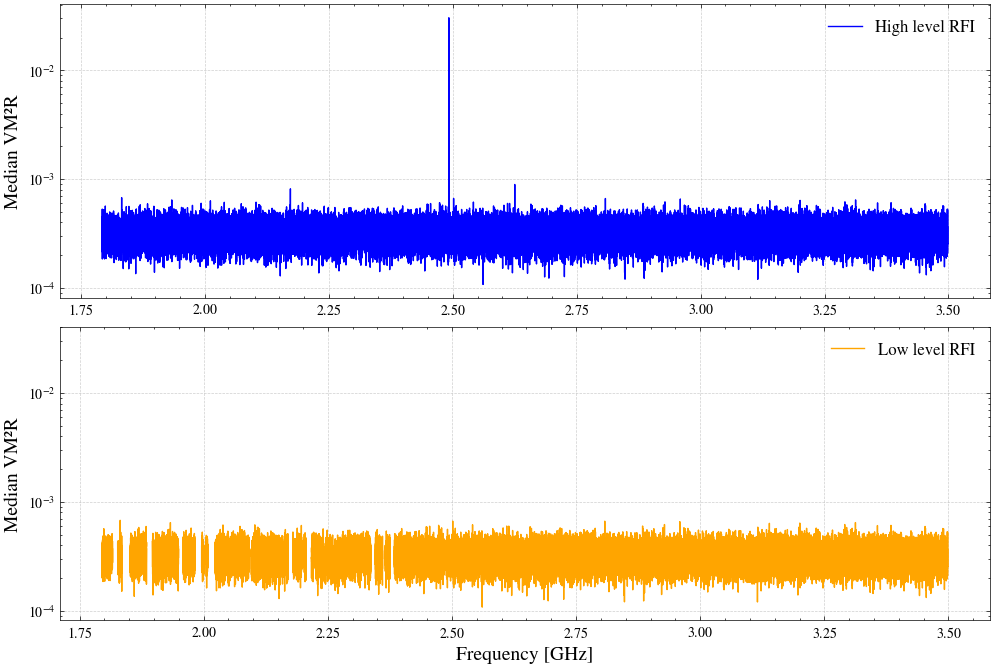

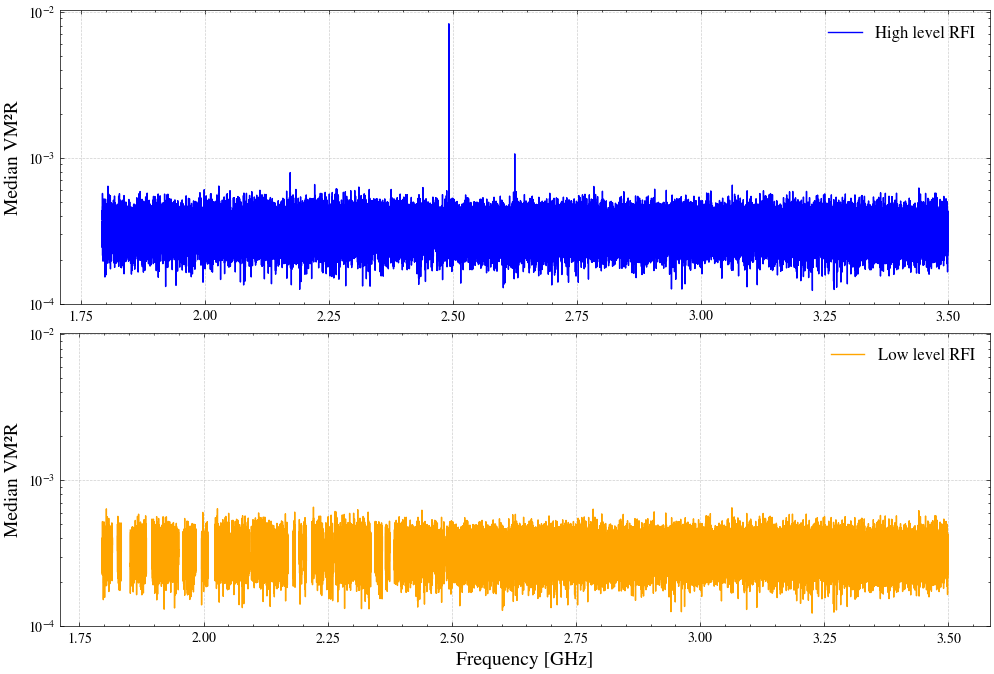

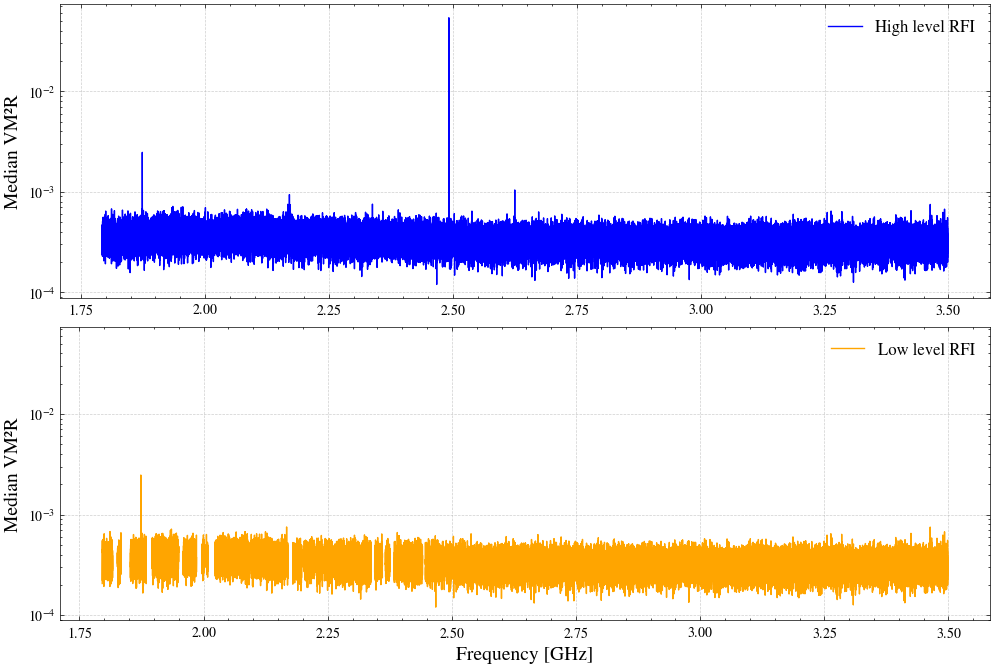

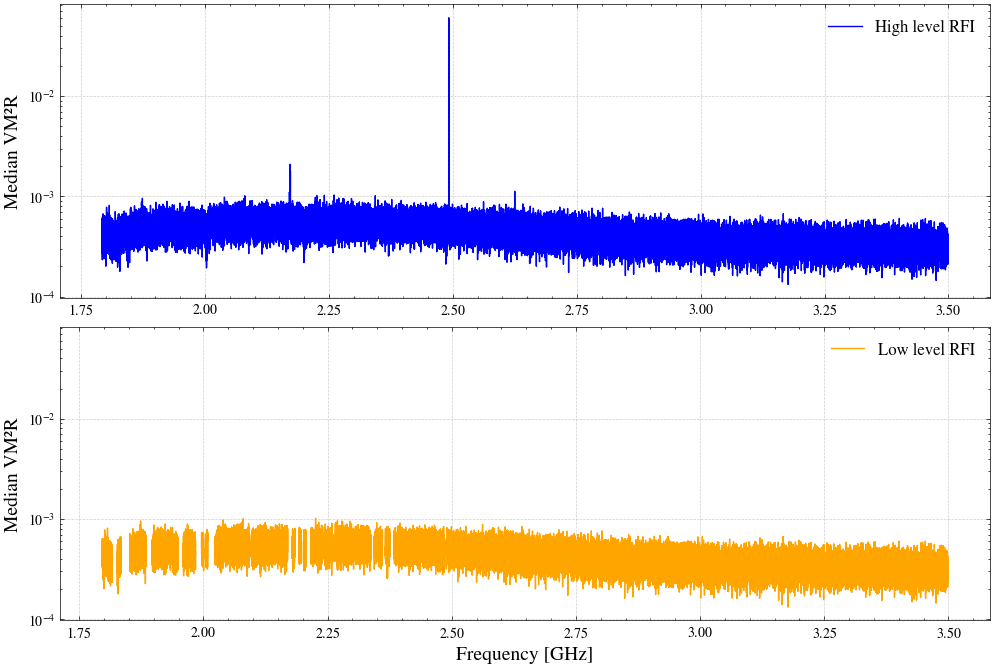

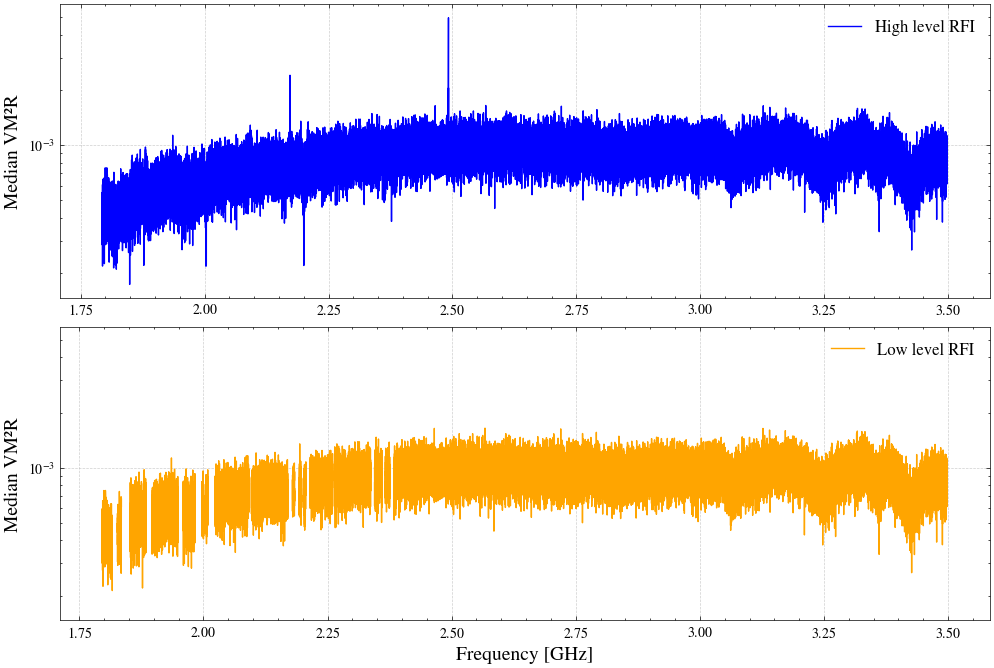

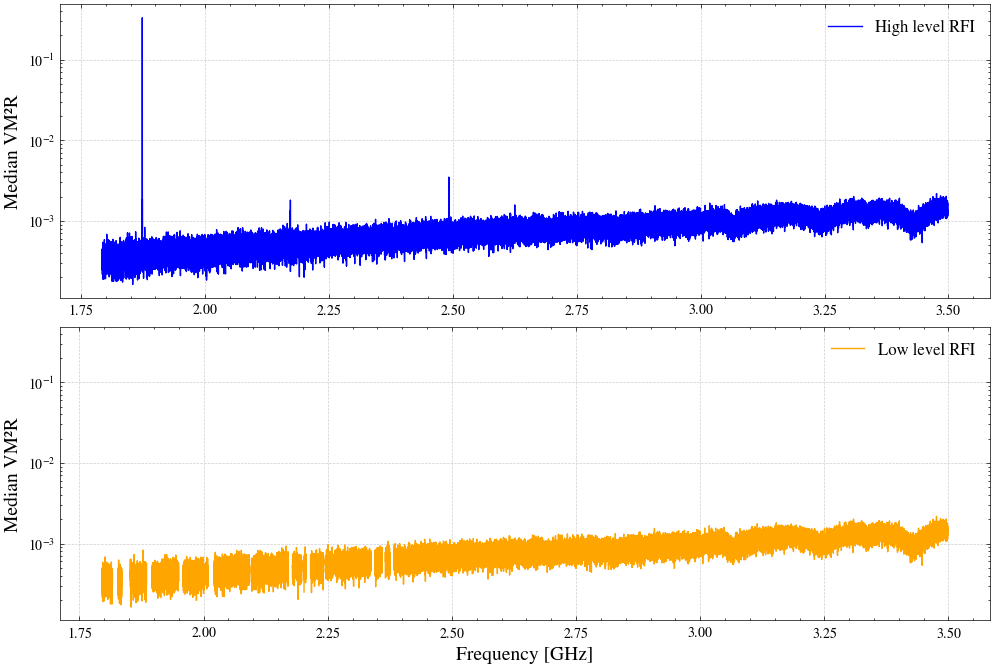

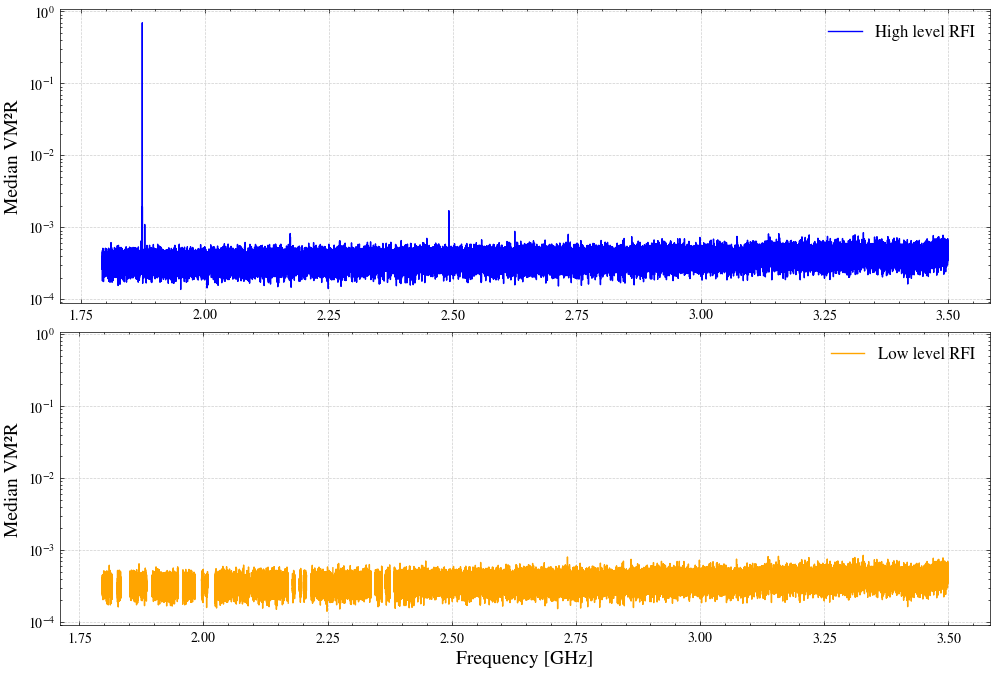

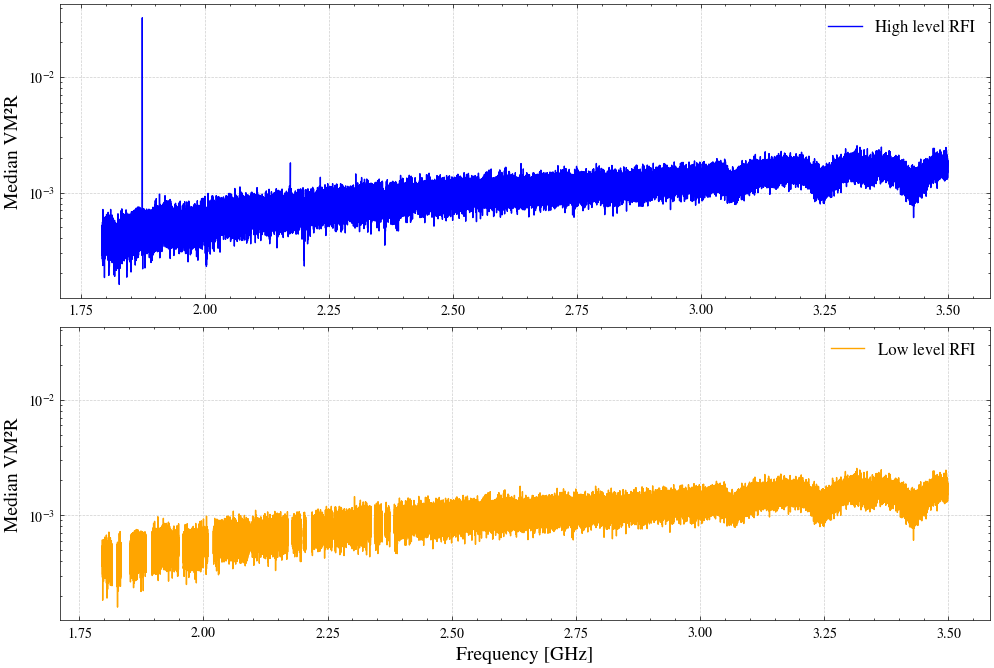

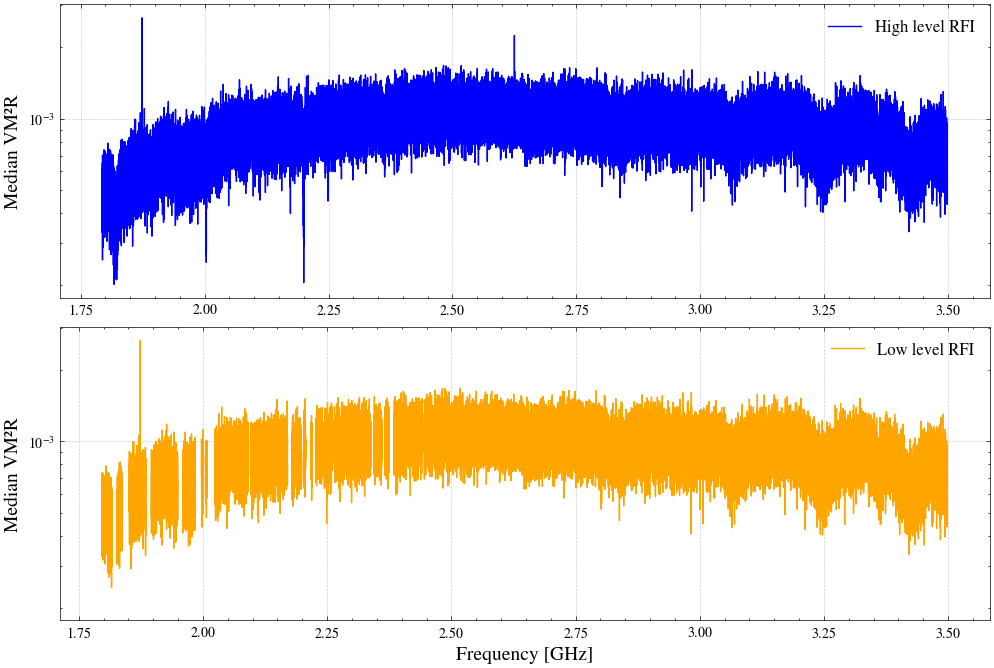

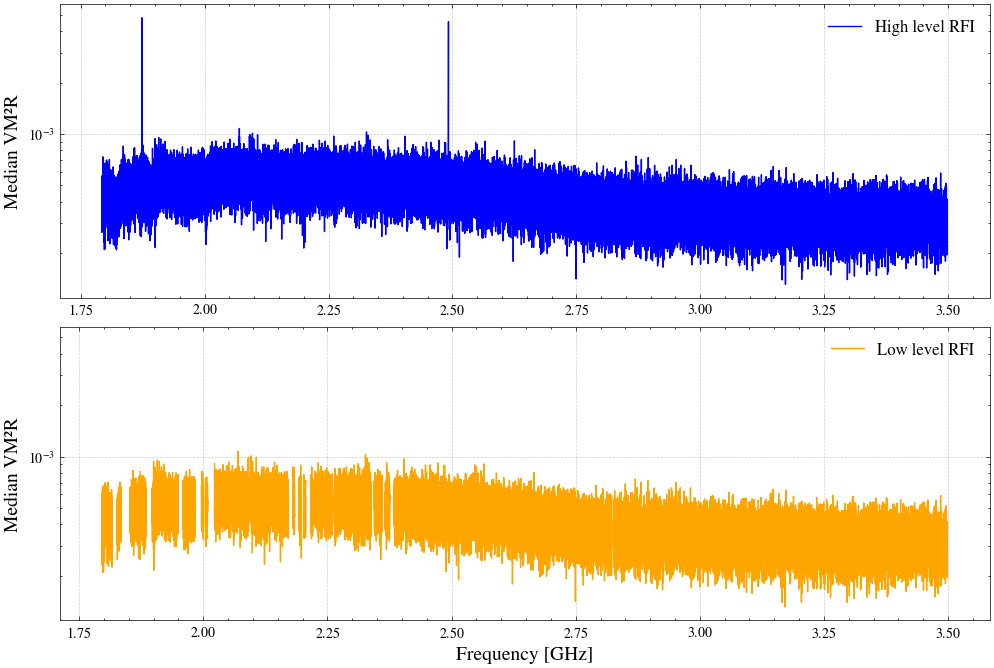

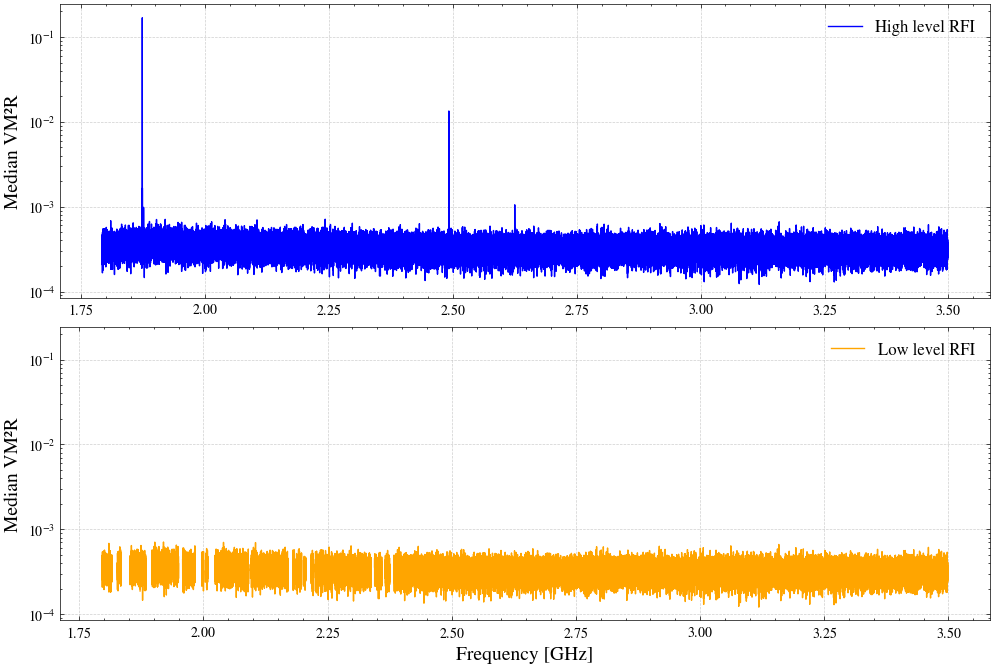

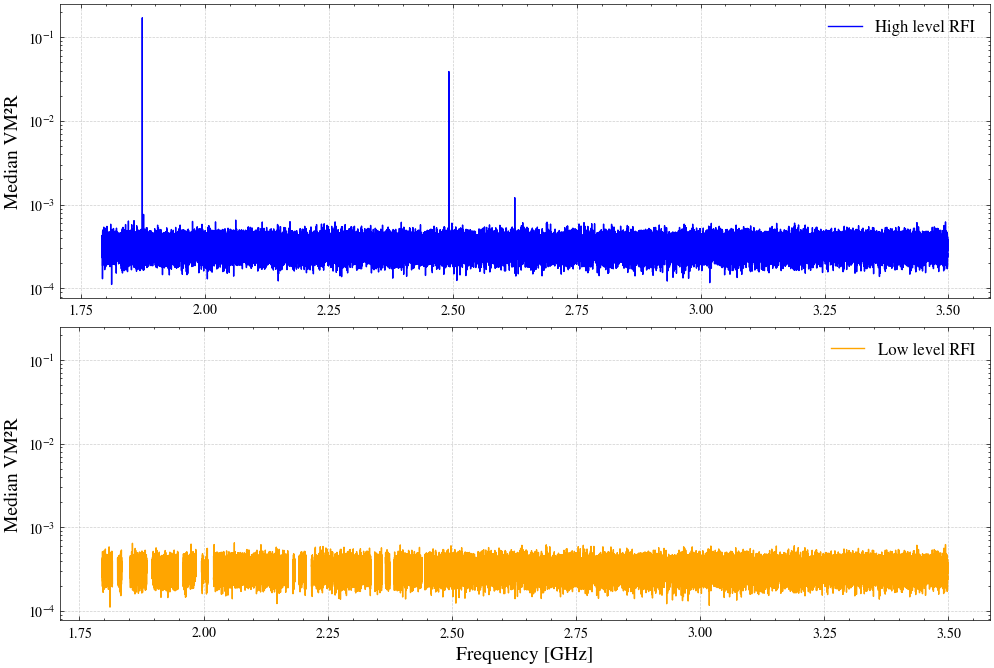

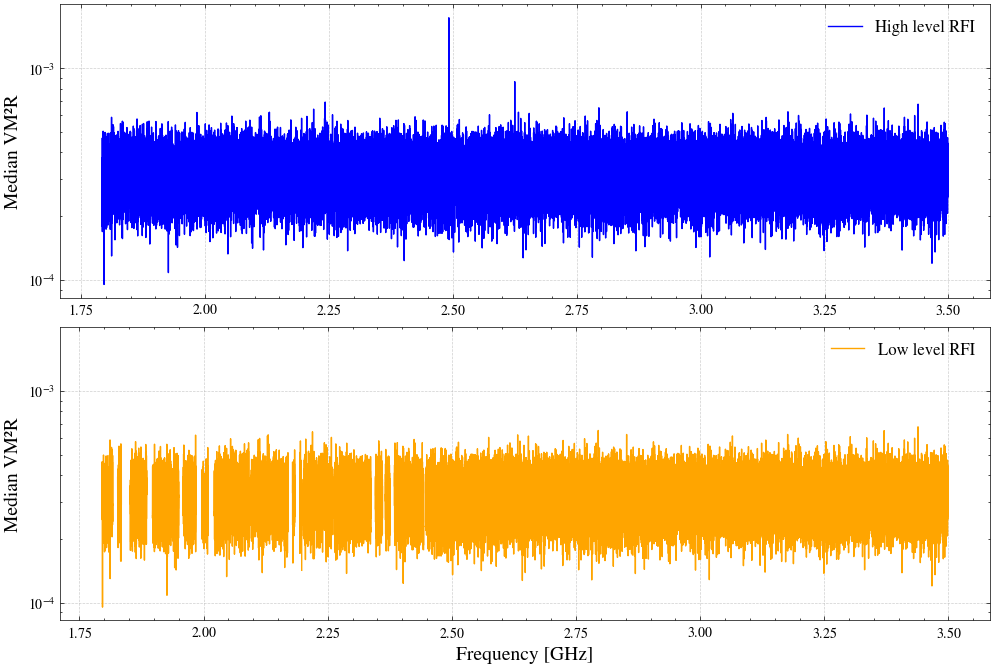

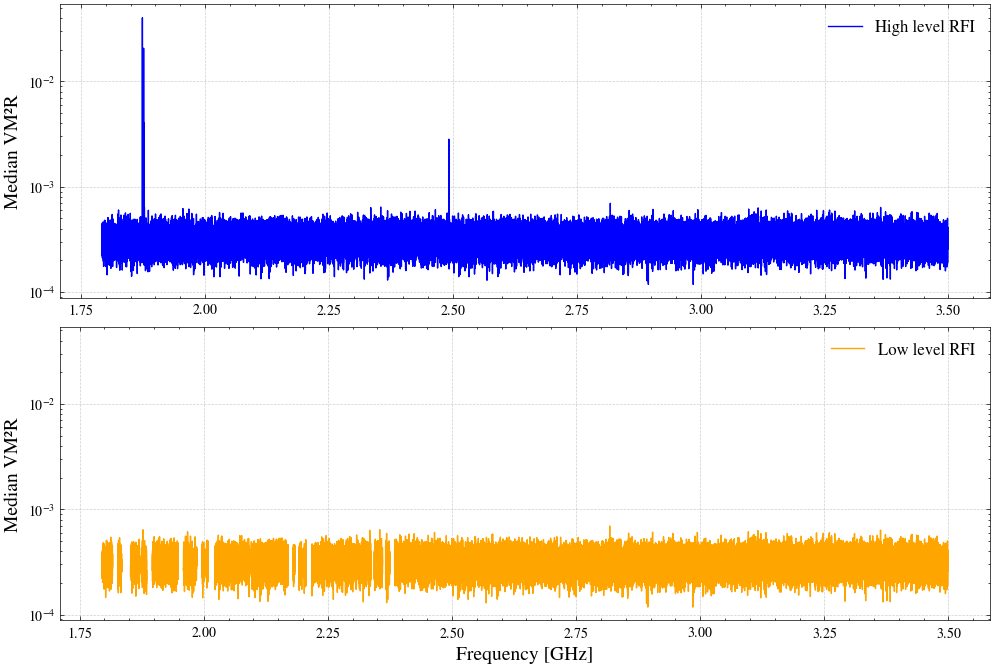

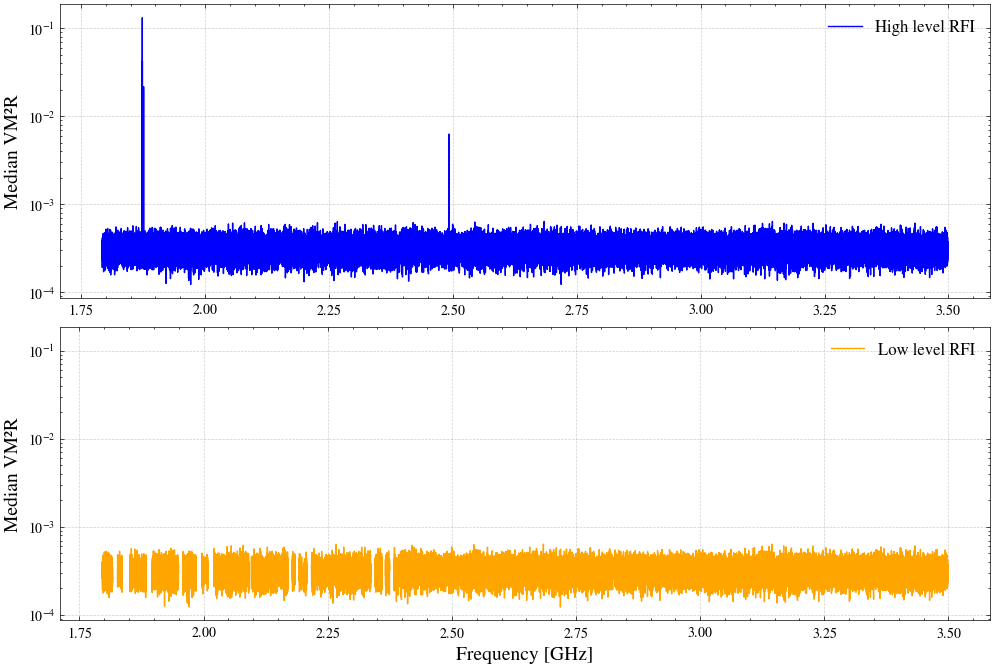

In [ ]:

for i in range(vm2r_array_high.shape[0]):
    
    figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
    figure.subplots_adjust(hspace=0.1)
    ax[0].plot(mask_frequency, vm2r_array_high[i,:], color='b', label='High level RFI')  
    ax[0].set_ylabel("Median VM²R", fontsize=14)
    ax[0].grid(True, linestyle='--', alpha=0.6)
    ax[0].legend(fontsize=12)
    ax[0].semilogy()

    ax[1].plot(mask_frequency, vm2r_array_low[i,:], color='orange', label='Low level RFI')
    ax[1].set_xlabel("Frequency [GHz]", fontsize=14)
    ax[1].set_ylabel("Median VM²R", fontsize=14)
    ax[1].grid(True, linestyle='--', alpha=0.6)
    ax[1].legend(fontsize=12)
    ax[1].semilogy()
    
    #break

In [ ]:
# Perform median over time for each frequency channel
vm2r_median_high = np.nanmedian(vm2r_array_high, axis=0)
vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)

# Perform median over time for each frequency channel without taking in consideration the NAN
vm2r_median_low_nan = np.median(vm2r_array_low, axis=0)

/tmp/ipykernel_1656983/547601547.py:3: RuntimeWarning: All-NaN slice encountered
  vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)


[]

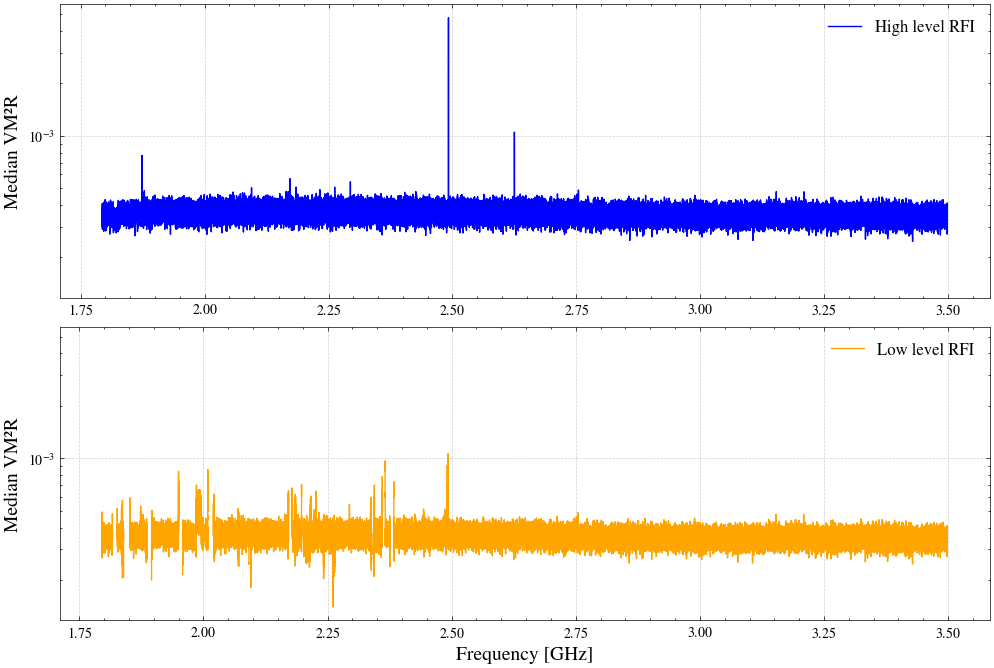

In [ ]:
figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
figure.subplots_adjust(hspace=0.1)
ax[0].plot(mask_frequency, vm2r_median_high, color='b', label='High level RFI')  
ax[0].set_ylabel("Median VM²R", fontsize=14)
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend(fontsize=12)
ax[0].semilogy()

ax[1].plot(mask_frequency, vm2r_median_low, color='orange', label='Low level RFI')
ax[1].set_xlabel("Frequency [GHz]", fontsize=14)
ax[1].set_ylabel("Median VM²R", fontsize=14)
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend(fontsize=12)
ax[1].semilogy()





In [ ]:
spectrum.max()

np.float64(9722921712302.352)

Text(0.5, 0, 'Frequency [GHz]')

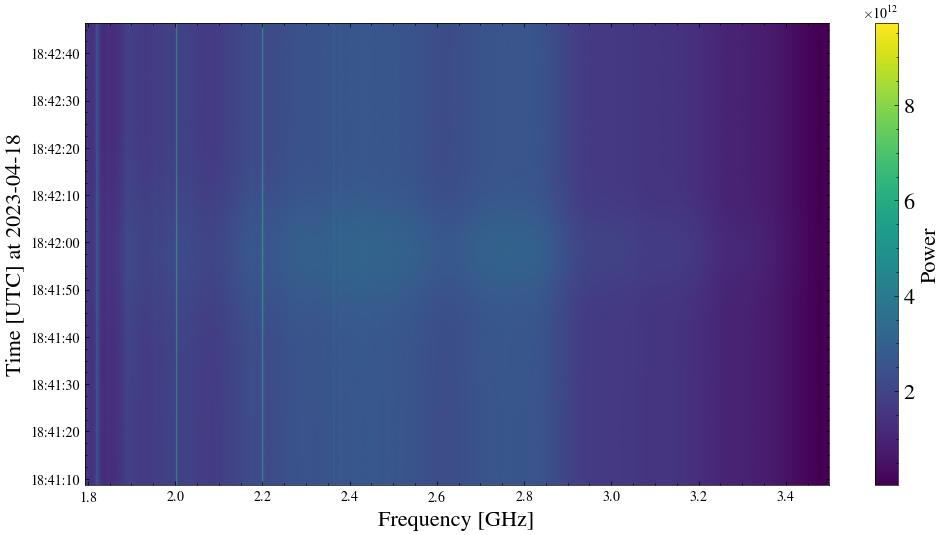

In [ ]:
plt.figure(figsize=(12, 6))

plt.imshow(spectrum, aspect='auto', 
extent=[frequency[0], frequency[-1], time_utc[0], time_utc[-1]],
origin='lower', cmap='viridis')

cbar = plt.colorbar()
cbar.set_label('Power', fontsize=16)
cbar.ax.tick_params(labelsize=16)    

plt.ylabel(f'Time [UTC] at {time_utc[0].strftime("%Y-%m-%d")}', fontsize=16)
plt.xlabel('Frequency [GHz]', fontsize=16)
